In [1]:
from typing import Any, Callable
import matplotlib.pyplot as plt
import json

from dataset_helpers import (
    filter_records,  # замена where в sql
    group_by_attributes,  # замена groupby
    aggregate_groups,  # замена применению агрегации к группированным данным
    missing_value_counts,  # подсчет пропущенных значений
    find_id_gaps,  # выводит список кортежей, где пара значений, не является соседями
    calculate_group_shares,  # подсчитывает долю
)

from aggregations import (
    count_records,  # замена count()
    count_unique,  # замена count(distinct x)
    max_value,  # замена MAX()
    min_value,  # замена MIN()
    mean_value,  # замена AVG()
    median_value,  # замена 0.5 квантили
    top_n,  # замена order by x desc limit n
)

from attribute_manager import (
    add_attribute,  # добавляет атрибут к текущим данным
    expand_list_attribute,  # разворачивает вложенный список атрибутов
)

from json_dict_processing import (
    extract_nested_value,
    process_dictionary_with_config,
)

## Анализ данных о Нобелевских лауреатах

### **Контекст проекта**
В этом задании мы будем работать с датасетом о лауреатах Нобелевской премии. Ваша задача — распарсить и проанализировать эти данные, ответив на ключевые вопросы о закономерностях вручения премий, демографических характеристиках лауреатов и исторических тенденциях.

### **Этап 1: Подготовка данных**

**Задача:** На этом этапе вам надо собрать структурированный список словарей с информацией о лауреатах и призах. Приведем начало нужного нам датасета.

``` {code:python}
[{'id': '745',
  'name': 'A. Michael Spence',
  'gender': 'male',
  'birth_year': 1943,
  'country_birth': 'USA',
  'country_now': 'USA',
  'prizes_relevant': [{'prize_amount': 10000000,
    'prize_amount_adjusted': 15547541,
    'award_year': 2001,
    'category_en': 'Economic Sciences',
    'prize_status': 'received'}],
  'type_': 'person'},
 {'id': '102',
  'name': 'Aage N. Bohr',
  'gender': 'male',
  'birth_year': 1922,
  'country_birth': 'Denmark',
  'country_now': 'Denmark',
  'prizes_relevant': [{'prize_amount': 630000,
    'prize_amount_adjusted': 4304697,
    'award_year': 1975,
    'category_en': 'Physics',
    'prize_status': 'received'}],
  'type_': 'person'}]
  ```

Поскольку информация о лауреатах-людях и лауреатах-организациях структурирована по-разному, а также из-за того, что часть полей в json могут отсутстввовать, необходимо реализовать функции для процессинга словарей, которые будут достаточно обобщаемыми для обоих типов данных.

**Что нужно сделать:**

На входе информация о конкретном лауреате представляет из себя кучу вложенных друг в друга словарей. Из этой структуры нам надо получить плоский словарь вида {atribute: value}, где atribute --- это один из небольшого множества интересных нам атрибутов. При этом в исходном файле 
1. пути к атрибутам могут иметь разную длину
2. атрибуты могут отсутствовать
3. атрибуты могут нуждаться в дополнительной обработке (например, поле id в исходных словарях записано как строка.)

Поскольку наивная реализация такого обработчика оказывается довольно громоздкой, вам нужно создать файл json_dict_processing.py, в котором реализован высокоуровневый функционал для решения задачи "обработать вложенный json-словарь"

Главное требование к интерфейсу: 
по (вложенному) словарю о лауреате и конфигу (см ниже) надо получить плоский словарь вида {atribute: value}.

Достичь этого можно, например, таким набором функций

* `extract_nested_value(obj, keys)` - извлекает значение из вложенных структур данных по цепочке ключей

* `process_dictionary_with_config(dictionary, config)` - обрабатывает один словарь согласно словару-конфигу (формат конфига см ниже.)

* `process_list_of_dicts_with_config(list_of_dicts, config)` - обрабатывает список словарей, эта функция нужна чтобы обработать список призов.

* `create_processor(config, list_processor=False)` - создает готовый процессор с предзагруженной конфигурацией. В случае, если list_processor == True, внутрь процессора подается process_list_of_dicts_with_config, иначе process_dictionary_with_config.

**Замечание насчет последней функции.**

Планируемое применение этой функции примерно такое:
`laureate_processor = create_processor(PERSON_CONFIG, list_processor=False)`

То есть, create_processor возвращает функцию, которая реализует функционал process_dictionary_with_config но с уже заполненным конфигом. Это повышает читаемость кода и снижает риск перепутать конфиги из-за дублирования кода.


Помимо этого нужно создать файлы-конфиги для данных по призам, лауреатам-людям, и лауреатам-организациям.

КОНФИГ для функций process_dictionary_with_config и process_list_of_dicts_with_config имеет следующий вид
```python
  {'атрибут_который_берем_сырым': ['путь', 'к', 'данным'],  # или
  'атрибут_который_нужно_обработать': (['путь', 'к', 'данным'], функция_обработки)}
  ```
В случае, если атрибут можно взять в итоговый датасет сырым, в values() словаря-конфига будет список path_list.
Если же атрибут еще надо обработать, для него в поле config[attribute] будет tuple вида (path_list, function).

Примеры атрибутов, которые можно взять сырыми: имя, размер приза. Примеры атрибутов, которые нужно обработать: год вручения приза (в сырых данных есть только полная дата, записанная как строка)

После того, как будет создан core.py, создайте конфиги laureates_configs.py и prizes_configs.py

Постарайтесь провалидировать код с помощью assert-ов, вызываемых в ноутбуке или в .py-файлах.

пример использования: 

assert 1 == True

**Валидация**

В вашем случае assert должен взять простой словарик с одним вложенным полем и какой-нибудь конфиг-файл.
Также убедитесь, что при обработке данных собственно по лауреатам в них нет странностей (смотрите ниже) 

**Атрибуты для ПРИЗА (CONFIG_PRIZE, prizes_configs.py)**

- `prize_amount` - сумма приза → `prizeAmount`
- `prize_amount_adjusted` - скорректированная сумма приза → `prizeAmountAdjusted`
- `award_year` - год вручения приза (преобразуется в целое число) → `awardYear`
- `category_en` - категория на английском → `category.en`
- `prize_status` - статус приза → `prizeStatus`

**Атрибуты для ЧЕЛОВЕКА-ЛАУРЕАТА (CONFIG_PERSON, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - имя лауреата → `knownName.en`
- `gender` - пол → `gender`
- `birth_year` - год рождения (извлекается из даты) → `birth.date`
- `country_birth` - страна рождения → `birth.place.country.en`
- `country_now` - текущая страна → `birth.place.countryNow.en`
- `prizes_relevant` - список призов лауреата → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Атрибуты для ОРГАНИЗАЦИИ-ЛАУРЕАТА (CONFIG_ORG, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - название организации → `orgName.en`
- `founded_year` - год основания (извлекается из даты) → `founded.date`
- `country_founded` - страна основания → `founded.place.country.en`
- `country_now` - текущая страна → `founded.place.countryNow.en`
- `prizes_relevant` - список призов организации → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Вспомогательные функции:**

- `process_year(year_string)` - извлекает год из строки даты (формат "YYYY-MM-DD"). Функция находится в файле laureates_configs.py
- `prize_processor()` - создает процессор для обработки списков призов. Функция находится в файле prizes_configs.py
- `person_processor()` - создает процессор для данных о людях-лауреатах. Функция находится в файле laureates_configs.py
- `org_processor()` - создает процессор для данных об организациях-лауреатах. Функция находится в файле laureates_configs.py

К сожалению, по API доступ ограничен владельцем, поэтому читаю исходный `laureates.json`, используя пакетный менеджер и модуль `json`

In [2]:
with open("laureates.json", "r") as file:
    laureates = json.load(file)

Проверяю работу функций обработки входных данных несколькими проверками:

- проверка `extract_nested_value`, извлекающей значение по переданному списку ключей(пути), в моем случае зайти в `person` -> `name` -> получить value

- проверка `process_dictionary_with_config` на соответствие выходного объекта конфигу и обработке передаваемой в нем функции-обработки("25" -> 25)

- проверка `extract_nested_value` на универсальность, а именно, если атрибут(ключ) не найден по переданному списку ключей(пути) -> None, функция не падает с ошибкой `KeyError`

In [3]:
test_dict = {
    "person": {
        "name": "Angelina",
        "age": "21",
        "address": {"city": "Saratov", "zip": "000000"},
        "profession": "Data Analyst/Product Analyst",
    }
}

test_config: dict[
    str,
    list[str] | tuple[list[str], Callable[[Any], Any]]
] = {
    "name": ["person", "name"],
    "age": (["person", "age"], int),
    "city": ["person", "address", "city"],
    "profession": ["person", "profession"],
}

assert extract_nested_value(test_dict, ["person", "name"]) == "Angelina"

assert process_dictionary_with_config(test_dict, test_config) == {
    "name": "Angelina",
    "age": 21,
    "city": "Saratov",
    "profession": "Data Analyst/Product Analyst",
}

assert extract_nested_value(test_dict, ["person", "marital status"]) is None

После успешной проверки запускаю алгоритм на исходных данных лауреатов, получая список словарей нужной формы

In [4]:
from laureates_configs import (
    process_orgs,
    process_persons,
)  # реализуйте эти функции согласно описанной выше логике


def get_laureate_data(laureate):
    """
    Определите тип лауреата and соотв образом обработайте данных.

    Args:
        laureate: Dictionary with laureate data

    Returns:
        Processed laureate data with added "type_" field ("person" or "org")

    Determines type by:
    - "knownName" key → person (uses process_persons)
    - "orgName" key → org (uses process_orgs)
    """
    # YOUR CODE HERE

    if "knownName" in laureate:
        result = process_persons(laureate)
        result["type_"] = "person"

    elif "orgName" in laureate:
        result = process_orgs(laureate)
        result["type_"] = "org"

    else:
        raise ValueError("Unknown laureate type")

    return result


laureates_data = []

for laureate in laureates["laureates"]:
    laureates_data.append(get_laureate_data(laureate))

Провалидировала:

- целостность (не потеряны лауреаты),

- тип года вручения приза,

- тип извлеченного года рождения у человека-лауреата и года основания у организации-лауреата

In [5]:
assert len(laureates_data) == len(laureates["laureates"])

assert all(
    isinstance(prize["award_year"], int)
    for laureate in laureates_data
    for prize in laureate["prizes_relevant"]
)

assert all(
    laureate["birth_year"] is None or isinstance(laureate["birth_year"], int)
    for laureate in laureates_data
    if laureate["type_"] == "person"
)

assert all(
    laureate["founded_year"] is None or isinstance(laureate["founded_year"], int)
    for laureate in laureates_data
    if laureate["type_"] == "org"
)



### **Этап 2: EDA лауреатов**

EDA или Exploratory Data Analysis - первый шаг при работе с любыми данными.

Чтобы начать работать с этой секцией, проведите чисто технический анализ собранных данных.

1. Сколько всего записей?
2. Все ли значения полей заполнены?
3. Если нет, сколько пропусков в каждом из полей? Выведите ответ на этот вопрос в формате `{'field_name': missing_values}`. А какая доля пропусков?
5. Каковы максимальные и минимальные значения поля id и каким годам награждения они соответствуют? Есть ли записи с повторяющимися id? Есть ли пары айди, которые в отсортированном массиве айдишников различаются более, чем на один? 

При реализации ответов на эти вопросы, пользуйтесь теми же принципами, что описаны выше. Можете начать с плохого хакерского кода, однако в таком случае в маркдауне пропишите, как будете его обобщать и разносить по функциям и модулям. (об этом ниже)

В основном EDA пользуйтесь аккуратным кодом, разбитым на функции и файлы.

In [6]:
# YOUR CODE HERE

total = count_records(laureates_data)
print(f"Всего записей: {total}")

Всего записей: 1028


In [7]:
records_person = filter_records(laureates_data, lambda x: x["type_"] == "person")

print(f"Всего записей по лауреатам-людям: {count_records(records_person)}")
print(
    f"Всего записей по лауреатам-организациям: "
    f"{total - count_records(records_person)}"
)

Всего записей по лауреатам-людям: 1000
Всего записей по лауреатам-организациям: 28


In [8]:
# Специфическая функция, учитывающая особенности текущих данных


def count_rows_with_missing(data):
    """
    Считает записи с хотя бы одним пропуском в обязательных полях.
    """
    required_fields = {
        "person": [
            "id",
            "name",
            "gender",
            "birth_year",
            "country_birth",
            "country_now",
            "prizes_relevant",
        ],
        "org": [
            "id",
            "name",
            "founded_year",
            "country_founded",
            "country_now",
            "prizes_relevant",
        ],
    }

    return sum(
        any(record.get(field) is None for field in required_fields[record["type_"]])
        for record in data
    )


print(
    f"Число лауреатов, у которых пропущено хотя бы одно "
    f"обязательное для них значение из конфига: "
    f"{count_rows_with_missing(laureates_data)}"
)

Число лауреатов, у которых пропущено хотя бы одно обязательное для них значение из конфига: 7


In [9]:
groups = group_by_attributes(laureates_data, ["type_"])

for type_, records in groups.items():
    print(f"Пропущенные значения для типа лауреата \"{type_[0]}\":")

    for attr, count in missing_value_counts(records).items():
        rate = count / count_records(records) * 100
        print(f"  {attr}: {count} ({rate:.2f}%)")

Пропущенные значения для типа лауреата "person":
  birth_year: 0 (0.00%)
  country_birth: 3 (0.30%)
  country_now: 3 (0.30%)
  gender: 0 (0.00%)
  id: 0 (0.00%)
  name: 0 (0.00%)
  prizes_relevant: 0 (0.00%)
  type_: 0 (0.00%)
Пропущенные значения для типа лауреата "org":
  country_founded: 4 (14.29%)
  country_now: 4 (14.29%)
  founded_year: 1 (3.57%)
  id: 0 (0.00%)
  name: 0 (0.00%)
  prizes_relevant: 0 (0.00%)
  type_: 0 (0.00%)


In [10]:
print(f"Всего уникальных лауреатов: {count_unique(laureates_data, "id")}")

Всего уникальных лауреатов: 1028


In [11]:
groups = group_by_attributes(laureates_data, ["id"])

id_counts = aggregate_groups(groups, count_records)

duplicate_ids = {id_[0]: count for id_, count in id_counts.items() if count > 1}

print(f"Дубликаты: {duplicate_ids if duplicate_ids else 0}")

Дубликаты: 0


In [12]:
print(
    f"Количество пропусков в последовательности id: {len(find_id_gaps(laureates_data))}"
)

Количество пропусков в последовательности id: 24


In [13]:
int_ids = add_attribute(
    laureates_data,
    "id_int",
    lambda x: int(x["id"]) if x.get("id") is not None else None,
)

prize_records = expand_list_attribute(int_ids, "prizes_relevant")

min_id = min_value(int_ids, "id_int")
max_id = max_value(int_ids, "id_int")

print("Максимальное и минимальное значение id и соответствующий год:")
for items in filter_records(
    prize_records, lambda x: x["id_int"] == min_id or x["id_int"] == max_id
):
    print(f"    \"{items.get("id")}\" : {items.get("award_year")}")

Максимальное и минимальное значение id и соответствующий год:
    "1070" : 2026
    "1" : 1901



Поскольку это курс по Python, а не по статистике или визуализации данных, мы не задаем жесткие рамки того, что вы должны проанализировать.
Однако это отличная возможность представить себя в роли разработчика базы данных или, например, библиотеки pandas.

В коде нужно соблюдать следующие правила:

1. должны быть реализованы  несколько способов работы с данными (среднее/медианное/максимальное значение метрики, количество примеров, вывод топ-N объектов по значению метрики).
2. анализ выбранных вами тем должен включать в себя анализ метрик в тотале, по категориям и в динамике по годам или десятилетиям.
3. проанализировать стоит 2-3 темы. Вы можете использовать темы ниже или взять свои.
2. вывод ноутбука должен быть понятен обывателю. Это может быть визуализация в matplotlib/seaborn. Сопровождайте вывод markdown-ячейками с вашими  мыслями, пояснениями и инсайтами, которые удалось извлечь.
3. Нельзя использовать pandas и numpy, но можно вдохновляться их интерфейсом и функционалом при дизайне ваших функций.


Из пункта 2 следует, что вам придется работать не только с атрибутами лауреатов, но и самих призов.
Информацию о призах нужно доставать и записывать как атрибут уже лауреата. Функции, работающие с призами (например, факт того, что лауреат отказался от какого-то из призов) можно реализовать в ноутбуке, но если вы создаете более общие вспомогательные функции, выносите их в отдельные модули.

Мы рекомендуем следующую структуру кода:

* `dataset_helpers.py` в котором реализованы фильтрация списка словарей (плоских) по условиям (аналог sql-ного where), а также аналог sql-ного групбая. А также функция для применения агрегаций к списку словарей
* `aggregations.py` в котором реализованы функции расчета среднего/медианы/других эвристик и мб вывод топ n-значений по какой-то метрике.
* `atribute_manager.py` в котором реализован переиспользуемый интерфейс для добавления (и мб удаления) полей.

Замечание насчет group-by. 

На игрушесном примере она может работать примерно так:
```
    Входные данные: [
        {'name': 'Alice', 'country': 'USA', 'age': 25},
        {'name': 'Bob', 'country': 'UK', 'age': 30},
        {'name': 'Charlie', 'country': 'USA', 'age': 25}
    ]
    
    group_by_attributes(data, ['country', 'age']) → {
        ('USA', 25): [
            {'name': 'Alice', 'country': 'USA', 'age': 25},
            {'name': 'Charlie', 'country': 'USA', 'age': 25}
        ],
        ('UK', 30): [
            {'name': 'Bob', 'country': 'UK', 'age': 30}
        ]
    }
```

Замечание насчет agregations.py
1. Агрегации соответственно должны применяться к спискам вида [
    {'name': 'Alice', 'country': 'USA', 'age': 25},
    {'name': 'Charlie', 'country': 'USA', 'age': 25}
]
2. Пользуйтесь модулем statistics из стандартной библиотеки питона.


Эта структура одна из возможных для организации вашего кода, главное, чтобы эти достаточно общие функции блыи переиспользованы

----------

При анализе данных вам понадобятся более конкретные функции, например filter_by_num_prizes или output_metric_by_category. Их пишите прямо в ноутбуке и сопровождайте коментами.

Ниже мы приводим некоторые примеры вопросов, которые может быть интересно задать к данным, но если у вас есть желание, можете поисследовать датасет с любой интересной вам стороны!


**2.1. Топ-статистика по странам**
- Определите топ-5 стран по общему количеству лауреатов
- Постройте аналогичные рейтинги отдельно по категориям (физика, химия, медицина и т.д.)

**2.2. Возраст при награждении**
- Рассчитать средний возраст лауреатов на момент получения **первого** приза. Рассмотрите только лауреатов-людей.
- Исследуйте, как средний возраст получения первого приза различается по категориям
- Различаются ли средний и медианный возрасты? 

**2.3. Гендерное распределение**
- Как менялось количество женщин-лауреатов по десятилетиям?
- Сравните распределение лауреаток по категориям. Выведите значения суммарно за все годы и по декадам.
- В какой из категорий больше всего женщин лауреаток изначально и в последние пару десятилетий?

**2.4. Миграции лауреатов**
- У скольки лауреатов исходная страна и страна на момент вручения нобелевской премии различаются? Всегда ли это различие объясняется миграцией? Добавьте вспомогательное поле 'country_of_origin_adjusted_for_migration', чтобы различие между этим полем и страной на момент вручения объяснялось миграцией.
- Выявите страны с наибольшей долей "оттекших" и "притекших" лауреатов.
- Есть ли оттоки среди организаций?

**2.5. Многократные лауреаты**
- Найдите лауреатов, получившие больше одного приза. Кто получил больше 2 раз? 
- Совпадает ли категория второго приза с первой?  
- Сколько в среднем времени прошло между получением первой и второй премии?

**2.6 Отказы от премий**
- Определите, в каких категориях чаще отказывались от премий?
- Есть ли отказы среди организаций?

## 2.1. Топ-статистика по странам
- Определите топ-5 стран по общему количеству лауреатов
- Постройте аналогичные рейтинги отдельно по категориям (физика, химия, медицина и т.д.)

**Определение страны-лауреата**

В рассматриваемом наборе данных есть ряд атрибутов, описывающих страну лауреата:
- `birth.place.country.en`, сохраненный в виде `country_birth` - страна рождения кандидата под тем названием, которое она имела на тот момент
- `birth.place.countryNow.en`, сохраненный в виде `country_now` - страна рождения кандидата под тем названием, которое она имеет на текущий момент
- `nobelPrizes.affiliations.country.en` - страна оганизации, с которой лауреат был связан при награждении: университеты, исследовательские институты и т. д.
- `nobelPrizes.residences.country.en` - страны проживания лауреата на момент награждения
- `nobelPrizes.affiliations.countryNow.en` - страна оганизации, с которой лауреат был связан при награждении: университеты, исследовательские институты и т. д. (текущие названия)
- `nobelPrizes.residences.countryNow.en` - страны проживания лауреата на момент награждения (текущие названия)

Я остановилась на `country_now`

Ранее из файлов `dataset_helpers.py`, `attribute_manager.py`, `aggregations.py` были импортированы функции, позволяющие провести анализ (описание каждой отдельной функции представлено в соответствующих файлах), а именно:

- отфильтровать записи исходного набора данных так, чтобы в нем были только лауреаты, страна которых известна
- сгруппировать по country_now
- взять топ 5

У рассмотренного подхода есть ряд ограничений, если человек-лауреат мигрировал, то он попадет в группу страны своего рождения с актуальным названием. Единого подхода по определению страны, к которой принадлежит лауреат нет, и в официальных источниках встречаются различные распределения, я остановлюсь на изложенном выше.

**Топ 5 стран по числу лауреатов**

In [14]:
laureates_with_countries = filter_records(
    laureates_data, lambda x: x["country_now"] is not None
)

groups_by_countries = group_by_attributes(laureates_with_countries, ["country_now"])

counts_by_countries = aggregate_groups(
    groups_by_countries, lambda records: count_unique(records, "id")
)

print(top_n(counts_by_countries, 5))


USA: 306
United Kingdom: 96
Germany: 86
France: 66
Japan: 32


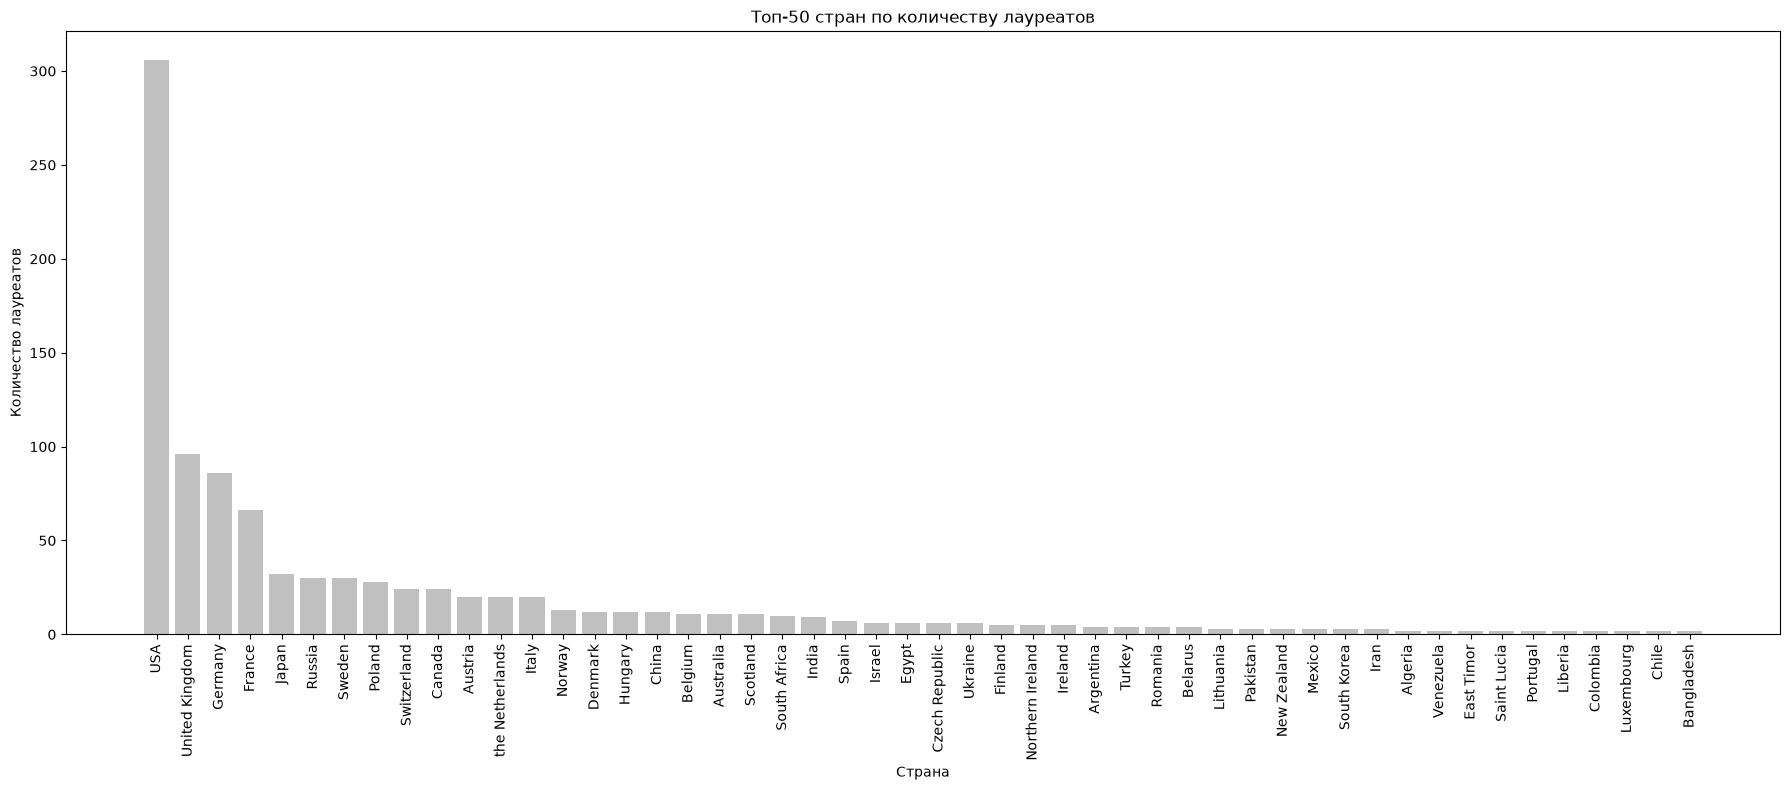

In [15]:
top_50 = sorted(counts_by_countries.items(), key=lambda item: item[1], reverse=True)[
    :50
]

countries = [country[0] for country, _ in top_50]
values = [value for _, value in top_50]

plt.figure(figsize=(18, 8))
plt.bar(countries, values, color="#C0C0C0")
plt.xlabel("Страна")
plt.ylabel("Количество лауреатов")
plt.title("Топ-50 стран по количеству лауреатов")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Общая статистика по числу лауреатов**

In [16]:
country_stats = [
    {"count": count}
    for count in counts_by_countries.values()
]

avg = mean_value(country_stats, "count")

print("Среднее:", round(avg, 2) if avg is not None else None)
print("Медиана:", median_value(country_stats, "count"))
print("Максимум:", max_value(country_stats, "count"))

Среднее: 11.87
Медиана: 2.0
Максимум: 306


Медиана сильно меньше среднего значения, поскольку большая часть лауреатов в распределении сосредоточена в небольшом числе стран, и 50% стран имеют до 2-х лауреатов.

**Топ 5 стран по числу лауреатов в каждой категории**

In [17]:
# Превращаем вложенные призы в отдельные записи
prize_records = expand_list_attribute(laureates_data, "prizes_relevant")

# Исключаем записи без страны
prize_records = filter_records(prize_records, lambda x: x["country_now"] is not None)

# Группируем по категории и стране
groups = group_by_attributes(prize_records, ["category_en", "country_now"])

# Считаем уникальных лауреатов в каждой группе
counts = aggregate_groups(groups, lambda records: count_unique(records, "id"))

# Выводим топ-5 стран отдельно по каждой категории
categories = sorted({category for category, country in counts})

for category in categories:
    country_counts = {
        country: count for (cat, country), count in counts.items() if cat == category
    }

    print(f"\n{category}:")
    print(top_n(country_counts, 5))



Chemistry:
USA: 59
Germany: 26
United Kingdom: 26
France: 12
Japan: 9

Economic Sciences:
USA: 56
United Kingdom: 7
Canada: 5
France: 5
the Netherlands: 4

Literature:
France: 12
USA: 10
Germany: 7
Poland: 7
Sweden: 7

Peace:
USA: 26
France: 12
Switzerland: 8
United Kingdom: 7
Germany: 5

Physics:
USA: 71
Germany: 27
United Kingdom: 25
France: 13
Japan: 12

Physiology or Medicine:
USA: 85
United Kingdom: 25
Germany: 20
France: 12
Sweden: 8


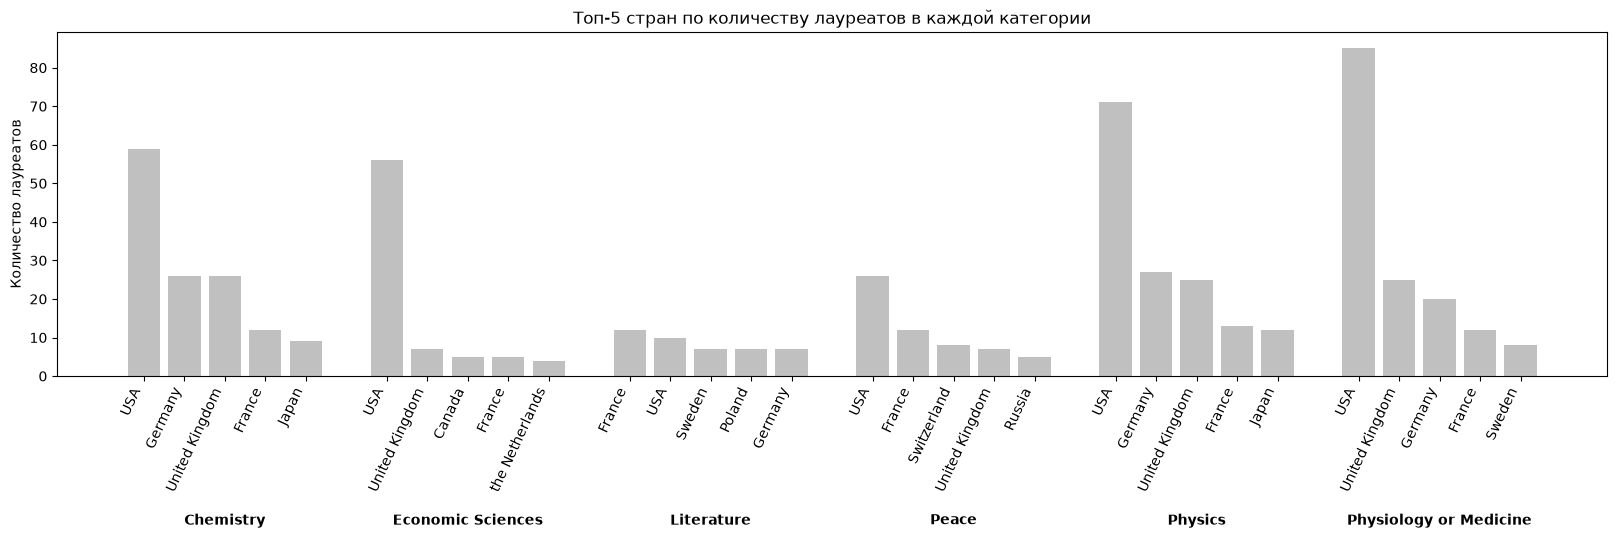

In [18]:
positions = []
countries = []
values = []
category_centers = []

for i, category in enumerate(categories):
    country_counts = {
        country: count for (cat, country), count in counts.items() if cat == category
    }

    top_5 = sorted(country_counts.items(), key=lambda item: item[1], reverse=True)[:5]

    start = i * 6  # 5 столбцов + промежуток

    for j, (country, count) in enumerate(top_5):
        positions.append(start + j)
        countries.append(country)
        values.append(count)

    category_centers.append((start + (len(top_5) - 1) / 2, category))


fig, ax = plt.subplots(figsize=(20, 8))

ax.bar(positions, values, width=0.8, color="#C0C0C0")

# Страны под столбцами
ax.set_xticks(positions)
ax.set_xticklabels(countries, rotation=65, ha="right")

# Категории ниже стран
for center, category in category_centers:
    ax.text(
        center,
        -0.4,
        category,
        ha="center",
        va="top",
        transform=ax.get_xaxis_transform(),
        fontsize=10,
        fontweight="bold",
    )

ax.set_ylabel("Количество лауреатов")
ax.set_title("Топ-5 стран по количеству лауреатов в каждой категории")
ax.set_ylim(bottom=0)

fig.subplots_adjust(bottom=0.45)
plt.show()

Видно, что:
- лидирующая позиция штатов сохраняются в каждой категории, произошло смещение на второе место в литературе
- в целом группы однородные, лидирующие страны из топ-5 в основном встречаются в лидерах не одной категории.

**Распределение числа лауреатов по 10-летиям**

In [19]:
prize_records_without_limits = expand_list_attribute(laureates_data, "prizes_relevant")

laureates_by_decade = add_attribute(
    prize_records_without_limits, "decade", lambda x: x["award_year"] // 10 * 10
)

groups_by_decade = group_by_attributes(laureates_by_decade, ["decade"])

counts_by_decade = aggregate_groups(
    groups_by_decade, lambda records: count_unique(records, "id")
)

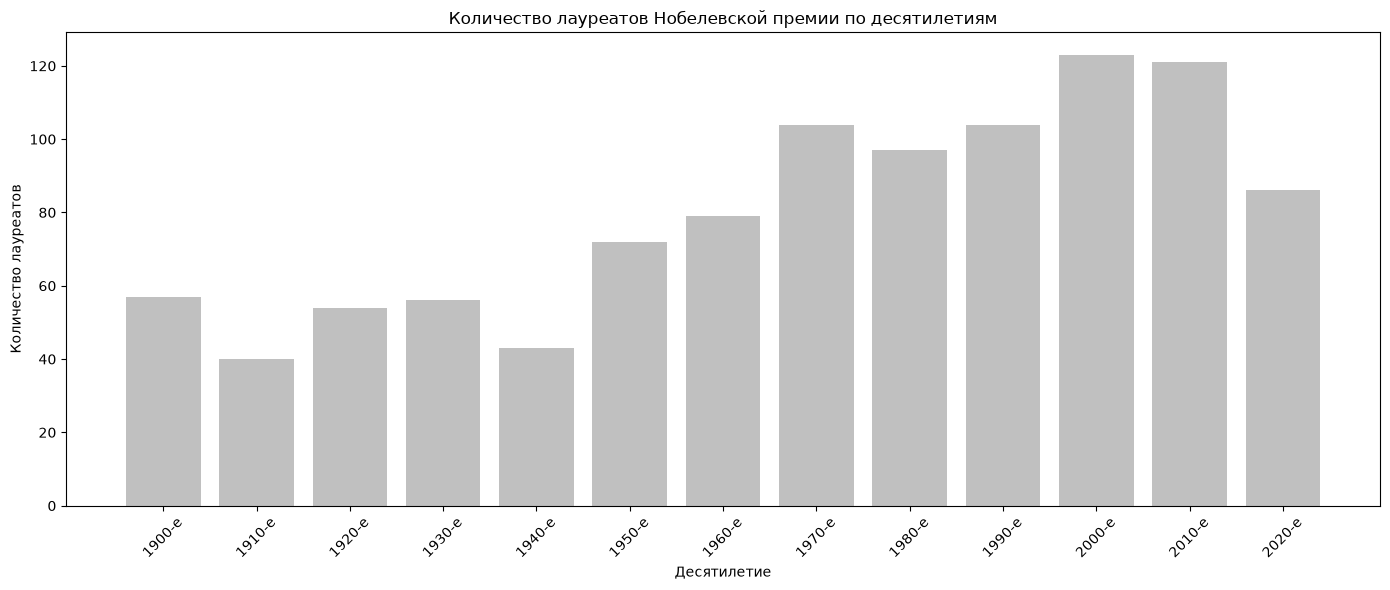

In [20]:
decades = sorted(counts_by_decade)

values = [counts_by_decade[decade] for decade in decades]
labels = [f"{decade[0]}-е" for decade in decades]

plt.figure(figsize=(14, 6))
plt.bar(labels, values, color="#C0C0C0")

plt.xlabel("Десятилетие")
plt.ylabel("Количество лауреатов")
plt.title("Количество лауреатов Нобелевской премии по десятилетиям")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Заметно, что пик числа лауреатов пришелся на нулевые

**Самая популярная для награждения категория в каждое 10-летие**

In [21]:
groups_by_decade_category = group_by_attributes(
    laureates_by_decade, ["decade", "category_en"]
)

counts_by_decade_categry = aggregate_groups(
    groups_by_decade_category, lambda records: count_unique(records, "id")
)

decades = sorted({decade for decade, category in counts_by_decade_categry})

for decade in decades:
    category_counts = {
        category: count
        for (dec, category), count in counts_by_decade_categry.items()
        if dec == decade and category is not None
    }

    print(f"\n{decade}-е годы:")
    print(top_n(category_counts, 1))


1900-е годы:
Peace: 14

1910-е годы:
Physics: 10

1920-е годы:
Physics: 12

1930-е годы:
Physiology or Medicine: 14

1940-е годы:
Physiology or Medicine: 14

1950-е годы:
Physics: 20

1960-е годы:
Physiology or Medicine: 25

1970-е годы:
Physics: 25

1980-е годы:
Physiology or Medicine: 23

1990-е годы:
Physics: 22

2000-е годы:
Physics: 28

2010-е годы:
Chemistry: 27

2020-е годы:
Chemistry: 18


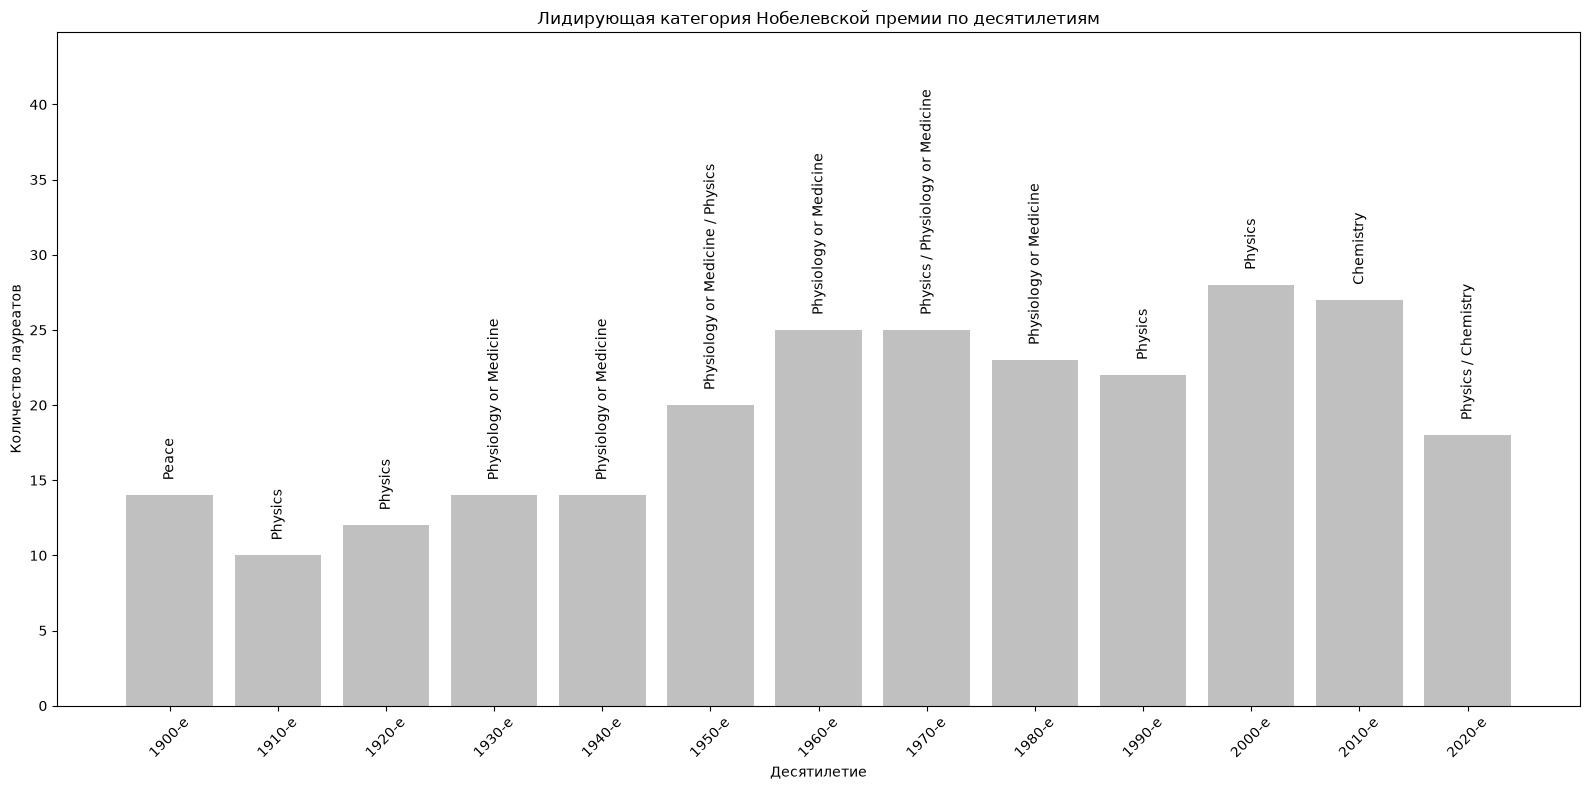

In [22]:
top_categories = []
values = []

for decade in decades:
    leader_category_counts = {
        category: count
        for (dec, category), count in counts_by_decade_categry.items()
        if dec == decade and category is not None
    }

    max_count = max(leader_category_counts.values())

    top_categories.append(
        " / ".join(
            category
            for category, count in leader_category_counts.items()
            if count == max_count)
    )

    values.append(max_count)

fig, ax = plt.subplots(figsize=(16, 8))

bars = ax.bar([f"{decade}-е" for decade in decades], values, color="#C0C0C0")

for bar, category in zip(bars, top_categories):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        category,
        ha="center",
        va="bottom",
        rotation=90,
    )

ax.set_xlabel("Десятилетие")
ax.set_ylabel("Количество лауреатов")
ax.set_title("Лидирующая категория Нобелевской премии по десятилетиям")
ax.set_ylim(0, max(values) * 1.6)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Видно, что в разрезе десятилетий больше всего лауреатов разово было по физике

**Лучшая страна по количеству лауреатов в каждое десятилетие**

In [23]:
groups_by_decade_country = group_by_attributes(
    laureates_by_decade, ["decade", "country_now"]
)

counts_by_decade_country = aggregate_groups(
    groups_by_decade_country, lambda records: count_unique(records, "id")
)

decades = sorted({decade for decade, country in counts_by_decade_country})

for decade in decades:
    decade_country_counts = {
        country: count
        for (dec, country), count in counts_by_decade_country.items()
        if dec == decade and country is not None
    }

    print(f"\n{decade}-е годы:")
    print(top_n(decade_country_counts, 1))


1900-е годы:
France: 9

1910-е годы:
France: 6

1920-е годы:
Germany: 10

1930-е годы:
USA: 14

1940-е годы:
USA: 14

1950-е годы:
USA: 21

1960-е годы:
USA: 22

1970-е годы:
USA: 33

1980-е годы:
USA: 33

1990-е годы:
USA: 43

2000-е годы:
USA: 54

2010-е годы:
USA: 39

2020-е годы:
USA: 28


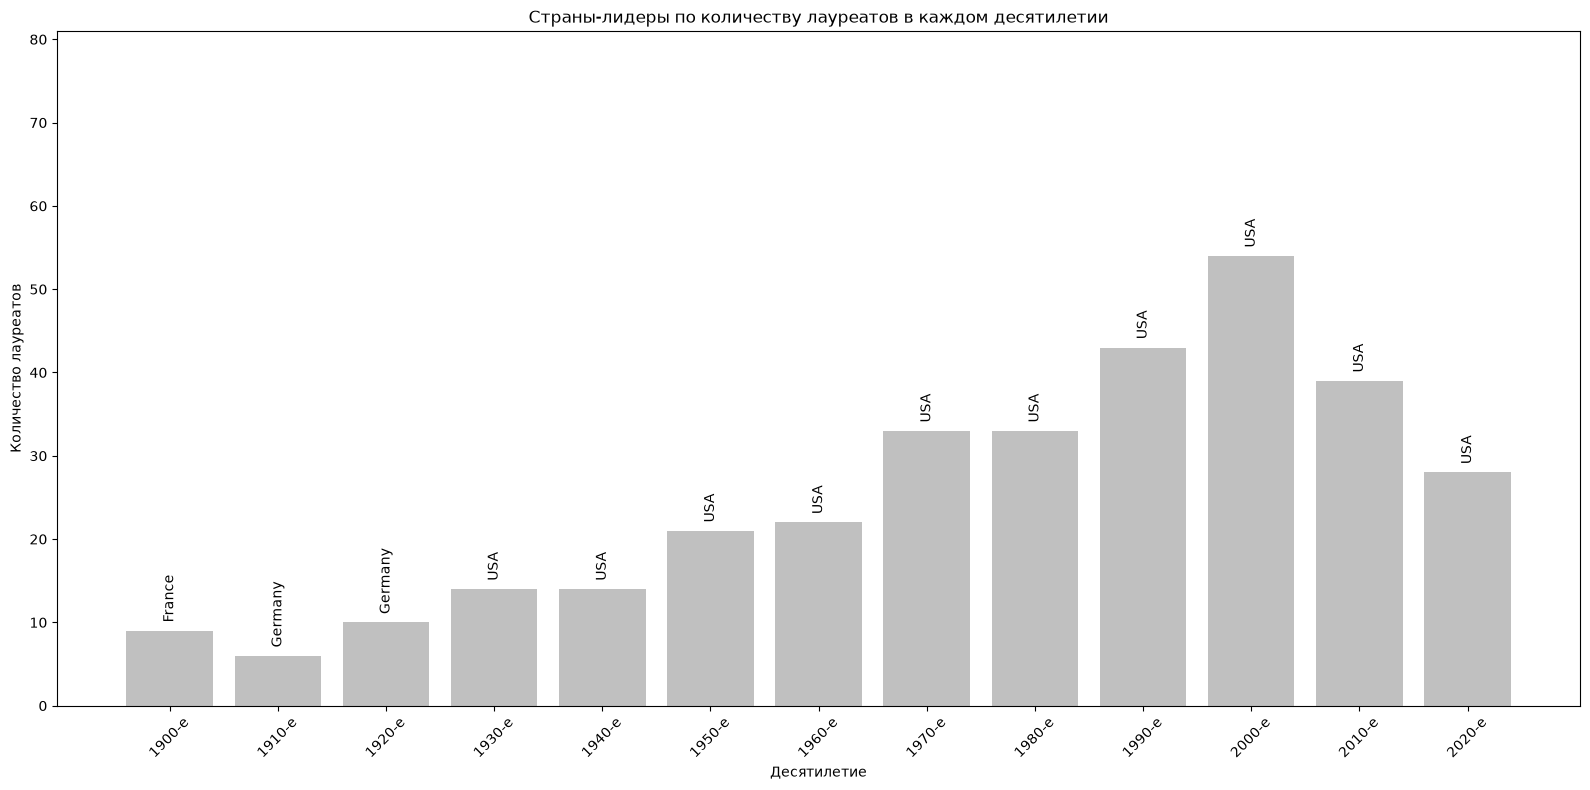

In [24]:
top_countries = []
values = []

for decade in decades:
    leader_country_counts = {
        country: count
        for (dec, country), count in counts_by_decade_country.items()
        if dec == decade and country is not None
    }

    top_country = max(
        leader_country_counts,
        key=lambda country: leader_country_counts[country]
    )

    top_countries.append(top_country)
    values.append(leader_country_counts[top_country])

fig, ax = plt.subplots(figsize=(16, 8))

bars = ax.bar([f"{decade}-е" for decade in decades], values, color="#C0C0C0")

for bar, country in zip(bars, top_countries):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        country,
        ha="center",
        va="bottom",
        rotation=90,
    )

ax.set_xlabel("Десятилетие")
ax.set_ylabel("Количество лауреатов")
ax.set_title("Страны-лидеры по количеству лауреатов в каждом десятилетии")
ax.set_ylim(0, max(values) * 1.5)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Просуммаризируем полученную информацию:** больше всего лауреатов было награждено в 2000-е, лидирующую часть из которых составили представители штатов, наиболее популярными в это время были награждения по физике

### Выводы

- Распределение Нобелевских лауреатов по странам происхождения неравномерно.

- Наибольшее количество лауреатов связано с США (306), Великобританией (96), Германией (86), Францией (66) и Японией (32).

- США лидируют в пяти из шести категорий премии, исключение составляет литература, где первое место занимает Франция (12 лауреатов).

- Страны, занимающие лидирующие позиции, в основном повторяются в разных категориях.

- В динамике по десятилетиям наибольшее количество уникальных лауреатов зафиксировано в 2000-х годах — 123 человека.

- Начиная с 1930-х годов США сохраняют лидерство по количеству лауреатов в каждом десятилетии.

**Ограничение:** принадлежность лауреата к стране определяется по актуальному названию страны его рождения (или основания организации), поэтому результаты не отражают гражданство или место проживания на момент награждения.

## 2.4. Миграции лауреатов

- У скольки лауреатов исходная страна и страна на момент вручения нобелевской премии различаются? Всегда ли это различие объясняется миграцией? Добавьте вспомогательное поле 'country_of_origin_adjusted_for_migration', чтобы различие между этим полем и страной на момент вручения объяснялось миграцией.
- Выявите страны с наибольшей долей "оттекших" и "притекших" лауреатов.
- Есть ли оттоки среди организаций?

**Обогащение данных**

Дополню данные информацией о стране проживания на момент награждения(первостепенный признак принадлежности к какой-либо стране) или страну организации, с которой лауреат связан на момент награждения(второстепенный признак принадлежности к стране)

In [25]:
# из исходных данных получаем список всех призов с указанием года,
# категории и стран, связанных с лауреатом на момент награждения,
# избавляясь от вложенности nobelPrizes
raw_prizes = expand_list_attribute(
    laureates["laureates"],
    "nobelPrizes",
    list_attributes=["awardYear", "category", "residences", "affiliations"],
)


# Специфическая функция для получения стран,
# связанных с лауреатом на момент награждения, приоритет отдается страны из резиденций
def get_award_places(prize):
    for attribute in ("residences", "affiliations"):
        places = expand_list_attribute(
            [prize], attribute, list_attributes=["countryNow"]
        )

        countries = {
            extract_nested_value(place, ["countryNow", "en"]) for place in places
        } - {None}

        if countries:
            return [
                {"country_at_award": country, "country_at_award_source": attribute}
                for country in sorted(countries)
            ]

    return [{"country_at_award": None, "country_at_award_source": None}]


# Собираем словарь вида (prize_id, award_year, category) -> list of countries
countries_by_prize = {
    (
        prize["id"],
        int(prize["awardYear"]),
        extract_nested_value(prize, ["category", "en"]),
    ): get_award_places(prize)
    for prize in raw_prizes
}

# разворачиваем laureates_data так, чтобы убрать вложенность
# в prizes_relevant, теперь каждая строка это награда, а не лауреат
prize_records = expand_list_attribute(laureates_data, "prizes_relevant")

# добавляем к каждой записи о награде список стран,
# связанных с лауреатом на момент награждения
prize_records = add_attribute(
    prize_records,
    "_award_places",
    lambda x: countries_by_prize[(x["id"], x["award_year"], x["category_en"])],
)

# разворачиваем _award_places, чтобы каждый кортеж однозначно определял одно вручение
laureates_flat = expand_list_attribute(prize_records, "_award_places")

Проверим покрытие данных новым атрибутом country_at_award

In [26]:
people_covered = filter_records(
    laureates_flat,
    lambda x: x["country_at_award"] is not None and x["type_"] == "person",
)
orgs_covered = filter_records(
    laureates_flat, lambda x: x["country_at_award"] is not None and x["type_"] == "org"
)
all_covered = filter_records(
    laureates_flat, lambda x: x["country_at_award"] is not None
)

print(f"Покрыто людей-лауреатов: {count_unique(people_covered, "id")}")
print(f"Покрыто организаций-лауреатов: {count_unique(orgs_covered, "id")}")
print(f"Покрыто лауреатов всего: {count_unique(all_covered, "id")}")


Покрыто людей-лауреатов: 985
Покрыто организаций-лауреатов: 2
Покрыто лауреатов всего: 987


Ранее установили, что всего уникальных лауреатов 1028, таким образом информация о предполагаемой текущей стране проживания есть у 96% лауреатов, при этом:

- лауреаты-люди покрыты почти полностью 985 из 1000

- лауреаты-организации почти не покрыты 2 из 28

Из чего следуют следующее ограничение - миграцию организаций нельзя достоверно отследить по имеющимся данным, поскольку атрибут `affiliations` не представлен на большей части данных и не имеет эквивалентной альтернативы.


**Подсчет числа мигрантов среди людей-лауреатов**

Подсчет осуществляется посредством сопоставления страны рождения (название актуальное на момент рождения лауреата) и страны награждения с актуальным названием

In [27]:
migrants = filter_records(
    laureates_flat,
    lambda x: (
        x["type_"] == "person"
        and x["country_at_award"] is not None
        and x["country_birth"] is not None
        and x["country_birth"] != x["country_at_award"]
    ),
)

print(f"Всего мигрантов: {count_unique(migrants, "id")}")


uniq_pare_countries = set()
for items in migrants:
    uniq_pare_countries.add((items["country_birth"], items["country_at_award"]))

print(uniq_pare_countries)

Всего мигрантов: 335
{('Russia', 'United Kingdom'), ('Austria', 'Germany'), ('Poland', 'Switzerland'), ('Pakistan', 'United Kingdom'), ('Egypt', 'Palestine'), ('Poland', 'USA'), ('Faroe Islands (Denmark)', 'Denmark'), ('the Netherlands', 'Switzerland'), ('Russian Empire', 'Poland'), ('Spain', 'USA'), ('Romania', 'Germany'), ('Norway', 'USA'), ('the Netherlands', 'USA'), ('USSR', 'Russia'), ('New Zealand', 'USA'), ('Germany', 'Canada'), ('France', 'Argentina'), ('West Germany', 'Germany'), ('USA', 'United Kingdom'), ('Finland', 'USA'), ('the Netherlands', 'United Kingdom'), ('Schleswig', 'Germany'), ('Russian Empire', 'France'), ('Egypt', 'USA'), ('New Zealand', 'United Kingdom'), ('South Africa', 'USA'), ('Canada', 'USA'), ('Egypt', 'United Kingdom'), ('Prussia', 'Germany'), ('Italy', 'Switzerland'), ('Romania', 'USA'), ('France', 'Germany'), ('Switzerland', 'USA'), ('Germany', 'Switzerland'), ('Germany', 'Sweden'), ('Italy', 'USA'), ('Tuscany', 'Italy'), ('British India', 'Bangladesh'

**Ограничения**

- Есть лауреаты связанные с несколькими странами в аффилиации при одном и том же награждении, поэтому при подсчете притока, они будут учтены во всех таких странах.

- По аффилиациям также нельзя однозначно судить о миграции, это лишь косвенный признак, важно учитывать это допущение при анализе и интерпретации.

- Если детальнее рассмотреть полученный список мигрантов, то можно заметить, что часть списка обусловлена политическими изменениями: изменение территориальных границ, смена названия и тд.

**Отделение миграции от географических и политических изменений**

Я введу дополнительный бинарный атрибут `country_of_origin_adjusted_for_migration`:

0, если лауреат попал в список мигрантов из-за политических изменений (`country_birth !=  country_at_award & country_at_award = country_now`),

1, иначе.

In [28]:
laureates_flat = add_attribute(
    laureates_flat,
    "country_of_origin_adjusted_for_migration",
    lambda x: (
        int(
            x["country_at_award"]
            != (x["country_birth"] if x["type_"] == "person" else x["country_founded"])
            and x["country_at_award"] != x["country_now"]
        )
        if (
            x["country_at_award"] is not None
            and x["country_now"] is not None
            and (
                (x["type_"] == "person" and x["country_birth"] is not None)
                or (x["type_"] == "org" and x["country_founded"] is not None)
            )
        )
        else None
    ),
)

# Пересчитываю число мигрантов
migrants = filter_records(
    laureates_flat,
    lambda x: (
        x["type_"] == "person" and x["country_of_origin_adjusted_for_migration"] == 1
    ),
)

print(count_unique(migrants, "id"))

300


- Определим долю "оттекших" и "притекших" лауреатов в разрезе страны, используя функцию `calculate_group_shares` из `dataset_helpers.py`
- Посмотрим на абсолютные значения для полноты понимания распределения

In [29]:
people = filter_records(
    laureates_flat,
    lambda x: (
        x["type_"] == "person"
        and x["country_of_origin_adjusted_for_migration"] is not None
    ),
)

migrants = filter_records(
    people, lambda x: x["country_of_origin_adjusted_for_migration"] == 1
)

outflow_shares = calculate_group_shares(
    people, migrants, ["country_now"], lambda records: count_unique(records, "id")
)

inflow_shares = calculate_group_shares(
    people, migrants, ["country_at_award"], lambda records: count_unique(records, "id")
)

print("Топ-5 стран по доле оттока:")
print(top_n(outflow_shares))

print("\nТоп-5 стран по доле притока:")
print(top_n(inflow_shares))

Топ-5 стран по доле оттока:
Algeria: 100.0
Azerbaijan: 100.0
Belarus: 100.0
Bosnia and Herzegovina: 100.0
Brazil: 100.0

Топ-5 стран по доле притока:
Belarus: 100.0
Mauritius: 100.0
Palestine: 100.0
Tunisia: 100.0
Israel: 60.0


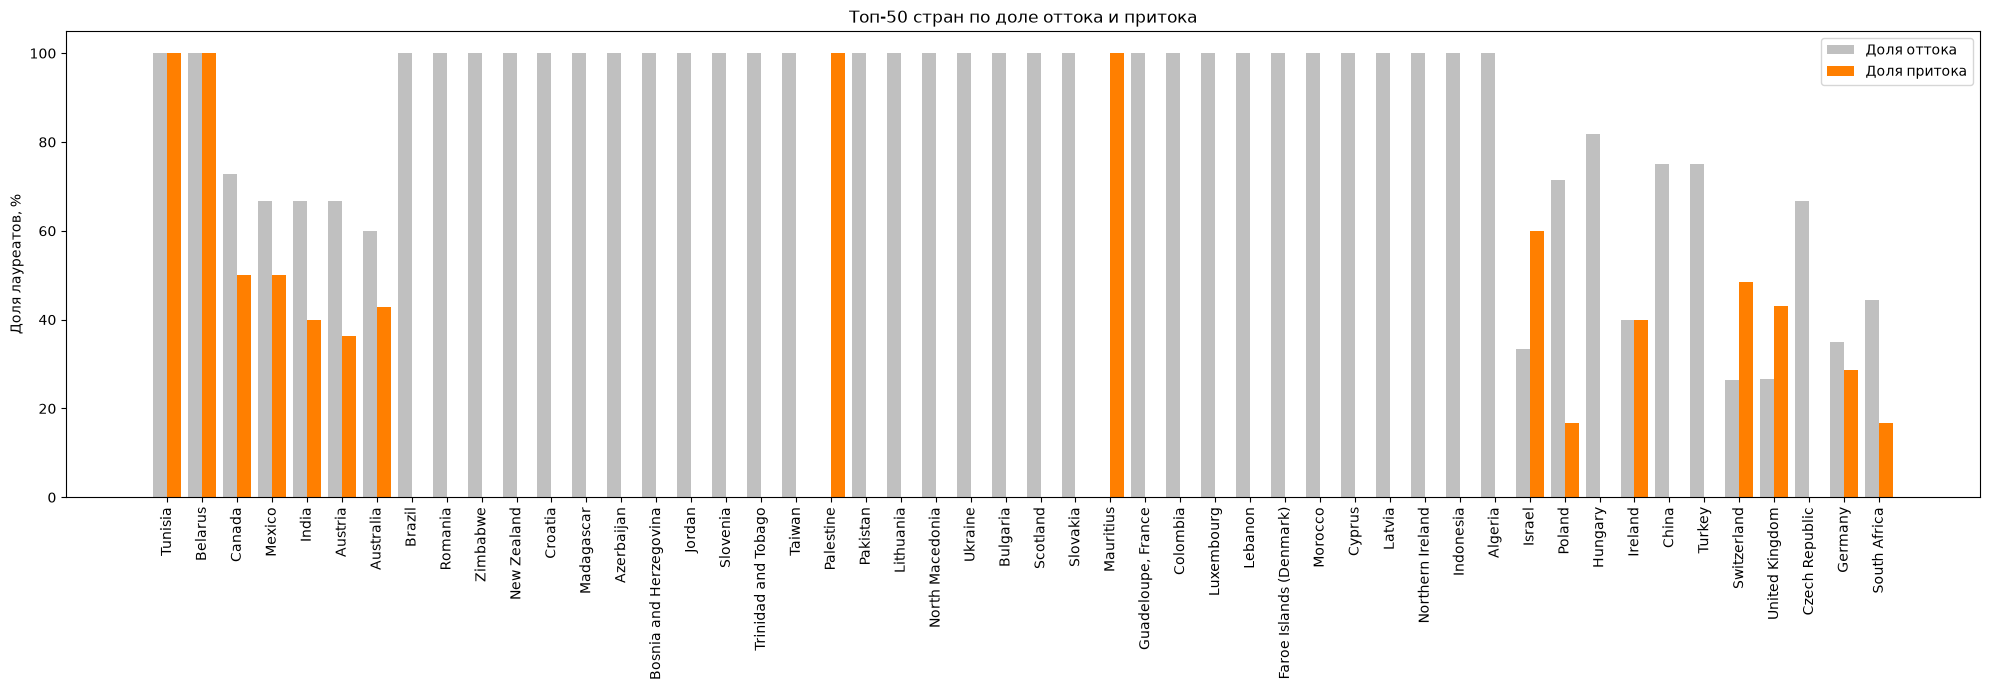

In [30]:
top_50 = sorted(
    set(outflow_shares) | set(inflow_shares),
    key=lambda country: outflow_shares.get(country, 0) + inflow_shares.get(country, 0),
    reverse=True,
)[:50]

countries = [country[0] for country in top_50]

outflow = [outflow_shares.get(country, float("nan")) for country in top_50]
inflow = [inflow_shares.get(country, float("nan")) for country in top_50]

x = range(len(countries))
width = 0.4

plt.figure(figsize=(20, 7))

plt.bar(
    [i - width / 2 for i in x],
    outflow,
    width=width,
    label="Доля оттока",
    color="#C0C0C0",
)
plt.bar(
    [i + width / 2 for i in x],
    inflow,
    width=width,
    label="Доля притока",
    color="#FF7F00",
)

plt.xticks(x, countries, rotation=90)
plt.ylabel("Доля лауреатов, %")
plt.title("Топ-50 стран по доле оттока и притока")
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
outflow_counts = aggregate_groups(
    group_by_attributes(migrants, ["country_now"]),
    lambda records: count_unique(records, "id"),
)

inflow_counts = aggregate_groups(
    group_by_attributes(migrants, ["country_at_award"]),
    lambda records: count_unique(records, "id"),
)

print("\nТоп-5 стран по абсолютному оттоку:")
print(top_n(outflow_counts, 5))

print("\nТоп-5 стран по абсолютному притоку:")
print(top_n(inflow_counts, 5))



Топ-5 стран по абсолютному оттоку:
Germany: 30
United Kingdom: 25
Poland: 20
France: 17
Canada: 16

Топ-5 стран по абсолютному притоку:
USA: 149
United Kingdom: 52
Germany: 25
France: 16
Switzerland: 15


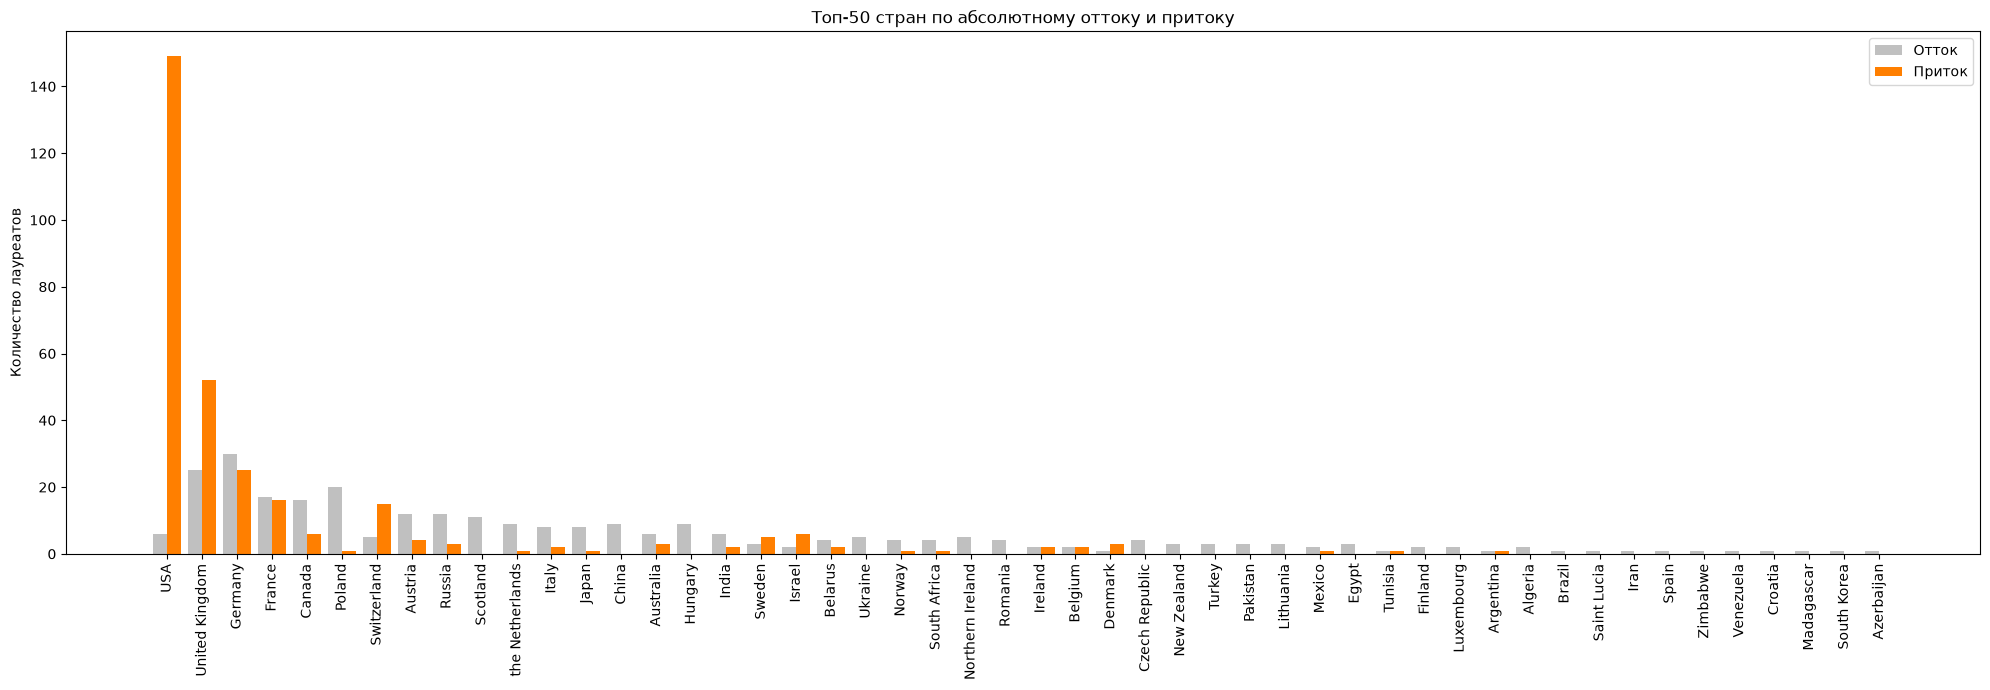

In [32]:
top_50 = sorted(
    set(outflow_counts) | set(inflow_counts),
    key=lambda country: outflow_counts.get(country, 0) + inflow_counts.get(country, 0),
    reverse=True,
)[:50]

countries = [country[0] for country in top_50]
outflow = [outflow_counts.get(country, 0) for country in top_50]
inflow = [inflow_counts.get(country, 0) for country in top_50]

x = range(len(countries))
width = 0.4

plt.figure(figsize=(20, 7))

plt.bar(
    [i - width / 2 for i in x], outflow, width=width, label="Отток", color="#C0C0C0"
)
plt.bar(
    [i + width / 2 for i in x], inflow, width=width, label="Приток", color="#FF7F00"
)

plt.xticks(x, countries, rotation=90)
plt.ylabel("Количество лауреатов")
plt.title("Топ-50 стран по абсолютному оттоку и притоку")
plt.legend()
plt.tight_layout()
plt.show()

Заметим, что доля притока лидирует среди Belarus, Mauritius, Palestine, Tunisia и Israel, однако с учетом распределения абсолютных значений, видно, что в целом высокая доля обусловлена небольшим числом лауреатов, в связи с чем, получаем искаженную картину популярности страны для переезда и научной деятельности.

**Мигранты среди организаций-лауреатов**

Ранее зафиксировали ограничение при работе со странами-лауреатами, тем не менее диагностически среди двух организаций, у которых есть параметр `affiliations`/ `residences` посмотрим на мигрантов:

In [33]:
orgs = filter_records(laureates_flat, lambda x: x["type_"] == "org")

org_migrants = filter_records(
    orgs, lambda x: x["country_of_origin_adjusted_for_migration"] == 1
)

org_with_affiliations = filter_records(
    orgs, lambda x: x["country_of_origin_adjusted_for_migration"] is not None
)

print(f"Всего организаций: {count_unique(orgs, "id")}")
print(f"Организаций с оттоком: {count_unique(org_migrants, "id")}")
print(
    f"Организаций с известной текущей страной: "
    f"{count_unique(org_with_affiliations, "id")}"
)

Всего организаций: 28
Организаций с оттоком: 0
Организаций с известной текущей страной: 1


**Отток в динамике 10-летий**

In [34]:
people_by_decade = add_attribute(people, "decade", lambda x: x["award_year"] // 10 * 10)

migrants_by_decade = filter_records(
    people_by_decade, lambda x: x["country_of_origin_adjusted_for_migration"] == 1
)

migration_shares_by_decade = calculate_group_shares(
    people_by_decade,
    migrants_by_decade,
    ["decade"],
    lambda records: count_unique(records, "id"),
)

for decade, share in sorted(migration_shares_by_decade.items()):
    print(f"{decade[0]}-е: {share}%")

1900-е: 29.09%
1910-е: 18.42%
1920-е: 20.37%
1930-е: 14.81%
1940-е: 35.0%
1950-е: 26.76%
1960-е: 31.08%
1970-е: 34.65%
1980-е: 37.23%
1990-е: 30.69%
2000-е: 26.89%
2010-е: 36.36%
2020-е: 38.16%


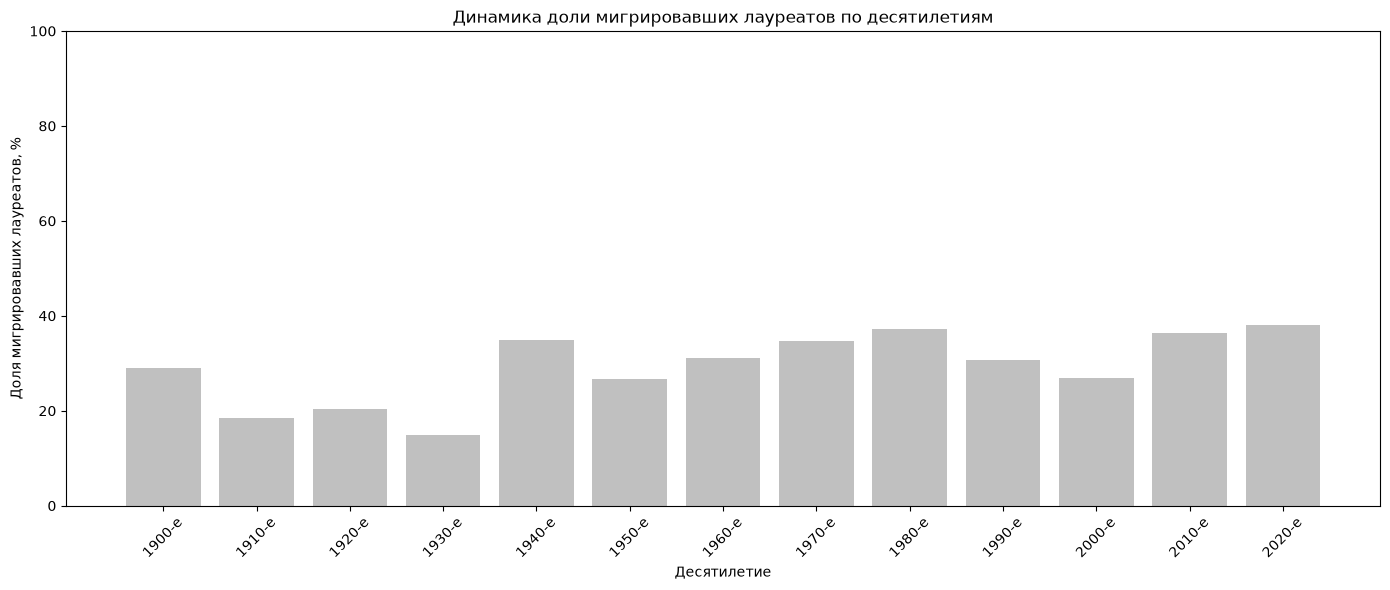

In [35]:
decades = sorted(migration_shares_by_decade)

values = [migration_shares_by_decade[decade] for decade in decades]

labels = [f"{decade[0]}-е" for decade in decades]

plt.figure(figsize=(14, 6))
plt.bar(labels, values, color="#C0C0C0")

plt.xlabel("Десятилетие")
plt.ylabel("Доля мигрировавших лауреатов, %")
plt.title("Динамика доли мигрировавших лауреатов по десятилетиям")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

Заметим, что наибольшая доля миграции в разрезе десятилетий наблюдается в 2020-х годах, то есть сейчас.

**Доля мигрантов в разрезе категорий**

In [36]:
migration_counts_by_category = aggregate_groups(
    group_by_attributes(migrants, ["category_en"]),
    lambda records: count_unique(records, "id"),
)

migration_shares_by_category = calculate_group_shares(
    people,
    migrants,
    ["category_en"],
    lambda records: count_unique(records, "id"),
)

for (category,), share in sorted(migration_shares_by_category.items()):
    count = migration_counts_by_category.get((category,), 0)
    print(f"{category}: {count} лауреатов ({share}%)")

Chemistry: 69 лауреатов (34.5%)
Economic Sciences: 32 лауреатов (32.65%)
Literature: 29 лауреатов (25.22%)
Peace: 20 лауреатов (18.52%)
Physics: 79 лауреатов (34.65%)
Physiology or Medicine: 71 лауреатов (30.21%)


### Выводы:

- Первоначальное сопоставление исторической страны рождения и страны на момент награждения выявило 335 лауреатов с различиями, однако такие несовпадения не всегда свидетельствуют о миграции, поскольку могут быть обусловлены изменением государственных границ и названий стран.

- После дополнительного сопоставления с актуальным названием страны рождения признак предполагаемой миграции был установлен для 300 уникальных лауреатов.

- В абсолютных значениях наибольший отток наблюдается из Германии (30), Великобритании (25) и Польши (20), а приток — в США (149), Великобританию (52) и Германию (25).

- Высокие процентные доли отдельных стран часто объясняются небольшим количеством лауреатов, поэтому абсолютные и относительные показатели необходимо рассматривать вместе.

- В разрезе категорий наибольшие доли предполагаемых мигрантов наблюдаются в физике (34,65%) и химии (34,50%), наименьшая — в категории премии мира (18,52%).

- В динамике максимальная доля мигрантов наблюдается в 2020-х годах (38,16%), т.к. десятилетие ещё не завершено, результат предварительный, однако уже занимает лидирующую позицию.

- Среди организаций оттоков не выявлено, но данных недостаточно для обобщения результата.

**Ограничение:** использованный показатель миграции является приближённым: аффилиация с организацией в другой стране не обязательно означает фактический переезд лауреата.

## 2.6 Отказы от премий

- Определите, в каких категориях чаще отказывались от премий?
- Есть ли отказы среди организаций?

**Распределение отказов по категориям**

In [37]:
restricted_prizes = filter_records(
    prize_records_without_limits,
    lambda x: (
        (x["prize_status"] == "restricted" or x["prize_status"] == "declined")
        and x["category_en"] is not None
    ),
)

groups_by_category = group_by_attributes(restricted_prizes, ["category_en"])

for group, records in groups_by_category.items():
    print(f"{group[0]}:")

    for rec in records:
        print(
            "    name:", rec.get("name"),
            "| status:", rec.get("prize_status"),
            "| year:", rec.get("award_year"),
        )

groups_by_category_counts = aggregate_groups(
    groups_by_category, lambda records: count_unique(records, "id")
)

for group, cnt in groups_by_category_counts.items():
    print(f"\n{group[0]} : {cnt}")

Literature:
    name: Boris Pasternak | status: restricted | year: 1958
    name: Jean-Paul Sartre | status: declined | year: 1964
Peace:
    name: Le Duc Tho  | status: declined | year: 1973

Literature : 2

Peace : 1


Видно, что таких случая всего 3, Борис Пастернак был вынужден отказаться от премии под давлением властей и имеет статус записи "restricted", Жан-Поль Сартр и Ле Дык Тхо отказались по личным убеждениям

**Отказы среди организаций**

In [38]:
org_refusals = filter_records(restricted_prizes, lambda x: x["type_"] == "org")

print(count_unique(org_refusals, "id"))

0


Так как в прошлом блоке мы уже рассмотрели все представленные случаи отказа, не удивительно отсутствие отказов среди организаций

### Выводы:

- выделить какие-либо закономерности в данном блоке не представляется возможным, так как случаи отказа от премии единичны и распределены по разным временным промежуткам(десятилетиям), тем не менее, 2 из 3 случаев отказов пришлись на литературу, а также все три случая не относятся к точным наукам

---------

## Бонусное задание на +2 балла


### Лингвистический анализ мотиваций**

**5.1. Анализ текстов мотиваций**
- Соберите корпус текстов мотиваций вручения премий. Для этого измените конфиг обработки призов.
- Выделите самые частые топ-50 слов. Какие из этих слов самые частые в принципе в английском языке (такие, как for, the и другие), а какие кажутся важными именно в контексте вручения Нобелевской премии (например, 'chemistry')?
- Самые частые слова, которые также являются частыми во всем английском языке занесите в отдельный конфиг-файл под названием `stopwords.py`. Вычистите их из текстов. Какие слова являются самыми частыми теперь? Сравните множества топ-10 самых частых слов по разным категориям


- Если есть желание, посчитайте TF-IDF + сравнените топ слов по этой метрике с просто самыми популярными словами)